# Analysis Pipeline

In this notebook we analyse the quality of the ScArches mapping using the *MappingAccessment* package. 

### Library Imports

In [1]:
# os.chdir('../')
import warnings
import os
from os.path import abspath
import importlib

import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np

import datetime
import statsmodels.stats.multitest as mtc
from MappingAssessment import MapAnalyzer, Plotter


### General settings

In [2]:
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

DATA_DIR = abspath(os.path.join(os.getcwd(), os.pardir, 'data'))
os.makedirs('Results', exist_ok=True)
RESULTS_DIR = os.path.join(os.getcwd(), 'Results')

In [3]:
#set parameters here
dataset = "Meyer_2019" # "Meyer_2021_5_prime"
ident = "Meyer_2019" # "Meyer_2021_5_prime"
query_color = "Blue"
condition = "X"
exclude = []

In [4]:
adata = sc.read(f'{DATA_DIR}/HLCA_full_v1.1_emb.h5ad')

In [5]:
adata

AnnData object with n_obs × n_vars = 2282447 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'ti

In [6]:
adata = adata[(adata.obs.core_or_extension=="core")|((adata.obs.dataset==dataset))]

### Preprocessing

Set clean cell labels on all levels and one label-column for transfer from curated metadata, assumed to be done in the package 

In [7]:
# In case that no umap based on the embedding is calculated, recalculate the UMAP
# sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30)
# sc.tl.umap(adata)

Initialize *AdataHandler* object. The *AdataHandler* makes sure all columns are named a standarized way. It also is able to perform a label transfer to the query.

In [8]:
adata_handler = MapAnalyzer.AdataHandler(
    adata,
    workspace = RESULTS_DIR,
    ident = ident + "/",  # folder that indentifies this workpartition
    log = True,  # create a logfile
)

Logger directory already exists


In [9]:
# Plotter object for the plots
plotter = Plotter.MapPlot(workspace = f"{adata_handler.workspace}/{ident}")

In [10]:
adata_handler.standarize_columns(
    condition_name=condition,  # condition name we want to distinguish
    query_dataset=dataset,  # query datasets
    cell_type_col=None,  # column name denoting celltype, none if no unified column
    dataset_col="dataset",  # column name denoting dataset
    sample_col="sample",  # column name denoting sample
    condition_col="lung_condition",  # column name denoting condition (abovementioned)
    subject_col="donor_id",  # column name denoting patients, subjects or donors
    disease_exclude=exclude,  # diseases to exclude from analysis
)

2023-06-16 07:47:23.536993	Standarizing columns...
2023-06-16 07:47:28.861478	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-06-16 07:47:28.864349	Finished column standarizing



Set appropriate levels for the cell type annotation

In [11]:
adata_handler.set_cell_type_levels(
    connect_threshold = 1, 
    annotation_columns = ['ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5'],
    finest_level_column = "ann_finest_level",
    unlabeled_tag = "nan")

2023-06-16 07:47:30.788130	starting with cell labels:
['AT0', 'AT1', 'AT2', 'AT2 proliferating', 'Adventitial fibroblasts', 'Alveolar Mph CCL3+', 'Alveolar Mph MT-positive', 'Alveolar Mph proliferating', 'Alveolar fibroblasts', 'Alveolar macrophages', 'B cells', 'Basal resting', 'CD4 T cells', 'CD8 T cells', 'Classical monocytes', 'Club (nasal)', 'Club (non-nasal)', 'DC1', 'DC2', 'Deuterosomal', 'EC aerocyte capillary', 'EC arterial', 'EC general capillary', 'EC venous pulmonary', 'EC venous systemic', 'Goblet (bronchial)', 'Goblet (nasal)', 'Goblet (subsegmental)', 'Hematopoietic stem cells', 'Hillock-like', 'Interstitial Mph perivascular', 'Ionocyte', 'Lymphatic EC differentiating', 'Lymphatic EC mature', 'Lymphatic EC proliferating', 'Mast cells', 'Mesothelium', 'Migratory DCs', 'Monocyte-derived Mph', 'Multiciliated (nasal)', 'Multiciliated (non-nasal)', 'Myofibroblasts', 'NK cells', 'Neuroendocrine', 'Non-classical monocytes', 'Peribronchial fibroblasts', 'Pericytes', 'Plasma cell

In [12]:
adata = adata_handler.get_adata()

Transfer celltype labels from reference data to query cells

In [13]:
adata_handler.transfer_labels(transfer_columns=["cell_label"], pickle=False)

2023-06-16 07:49:33.018845	Transferring labels...
2023-06-16 07:49:33.911053	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-06-16 07:49:34.221034	transferring cell_label
finished!


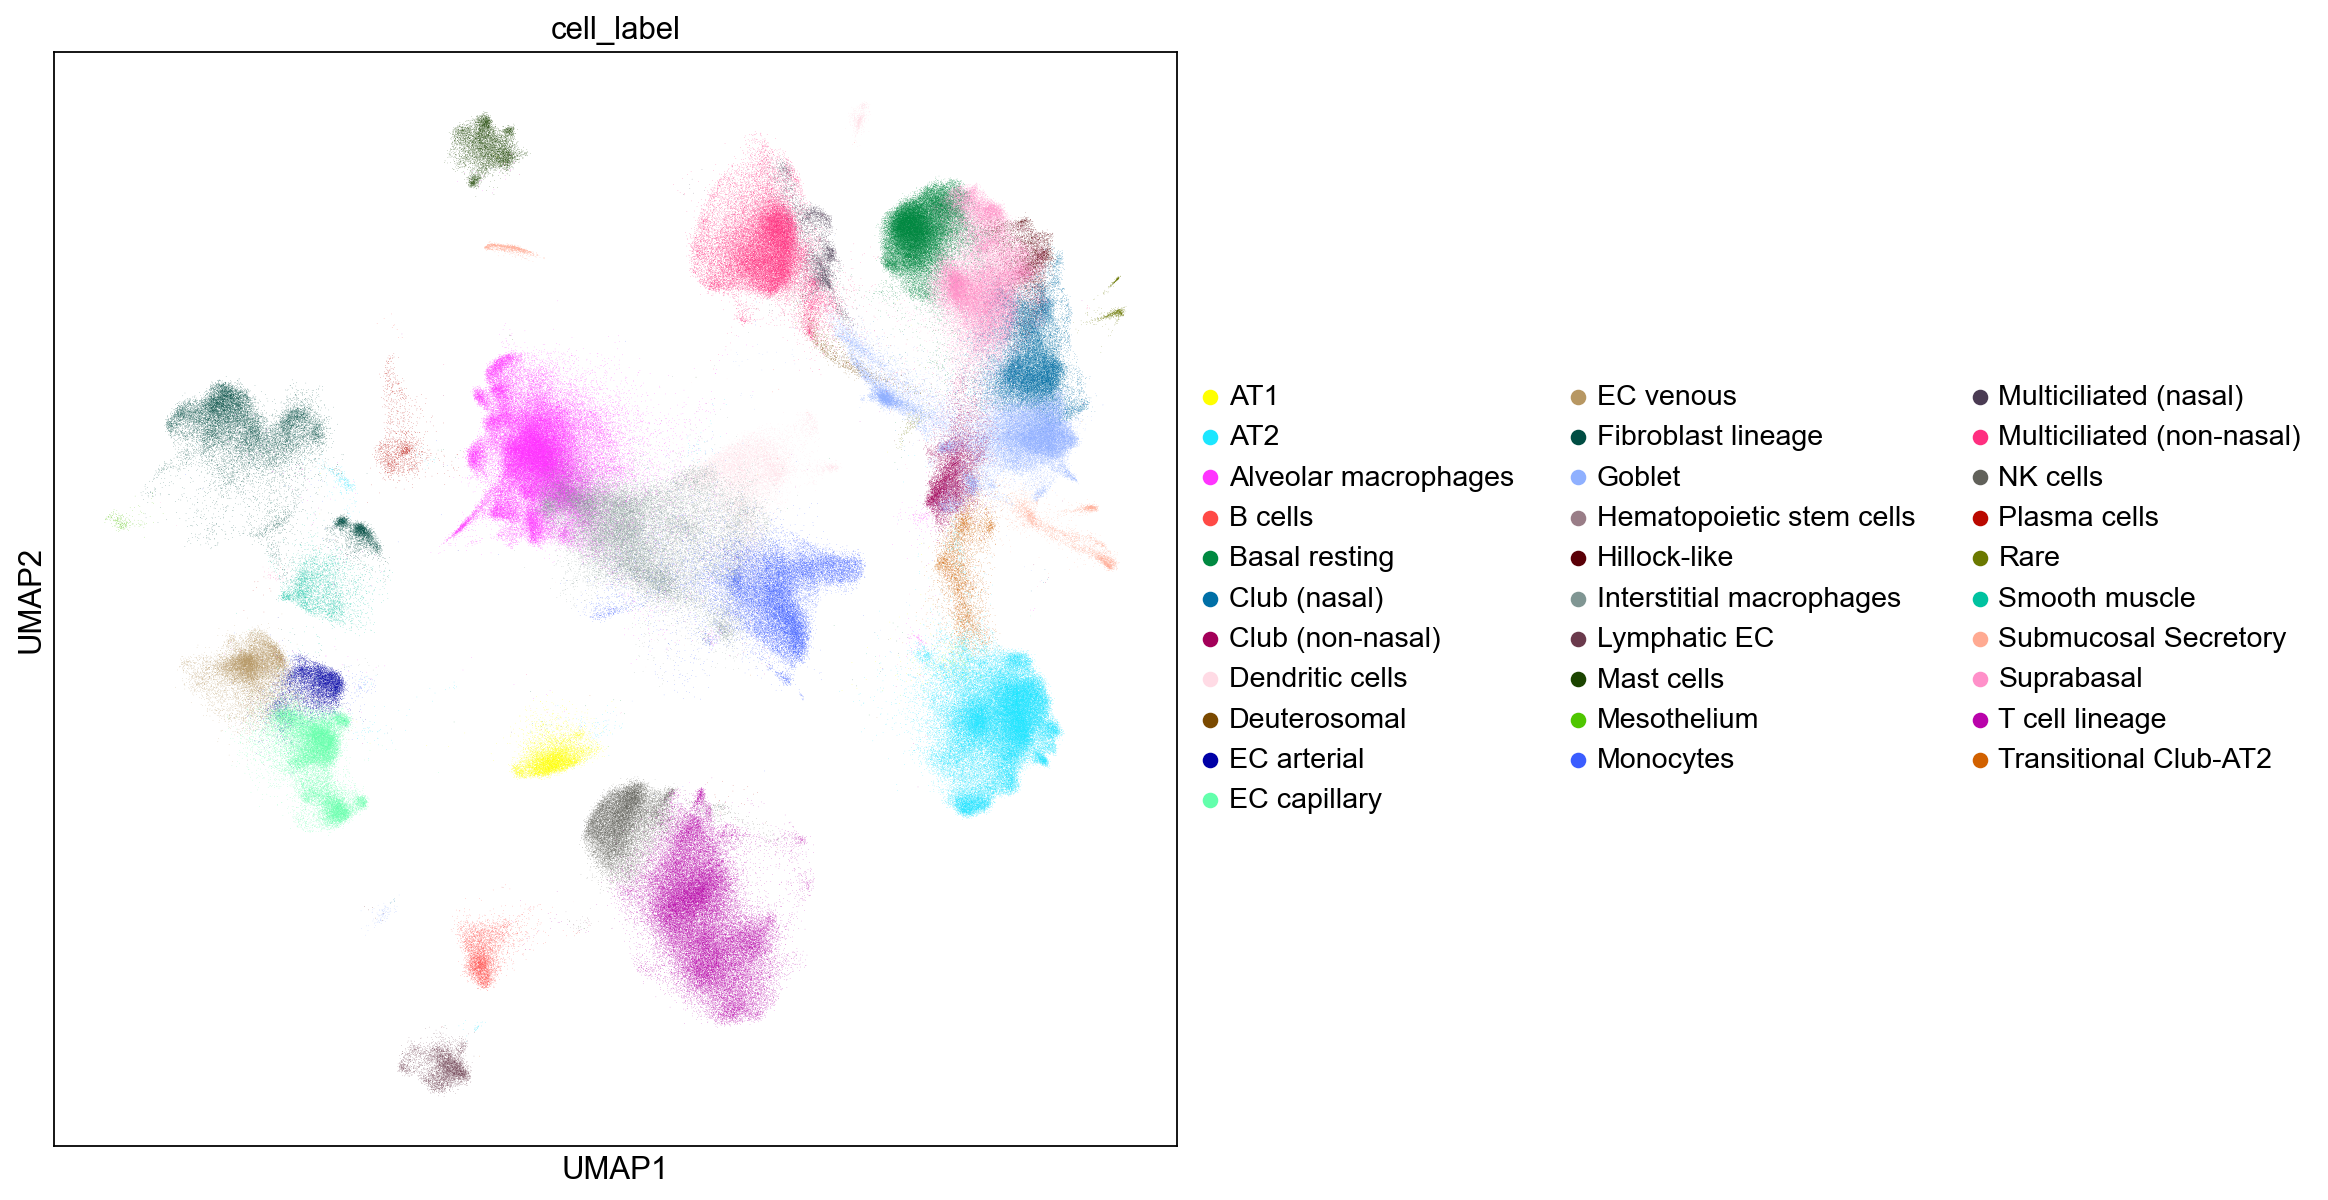

In [14]:
sc.pl.umap(adata, color="cell_label")

In [15]:
adata.obs.query_or_reference.cat.categories

Index(['query', 'reference'], dtype='object')

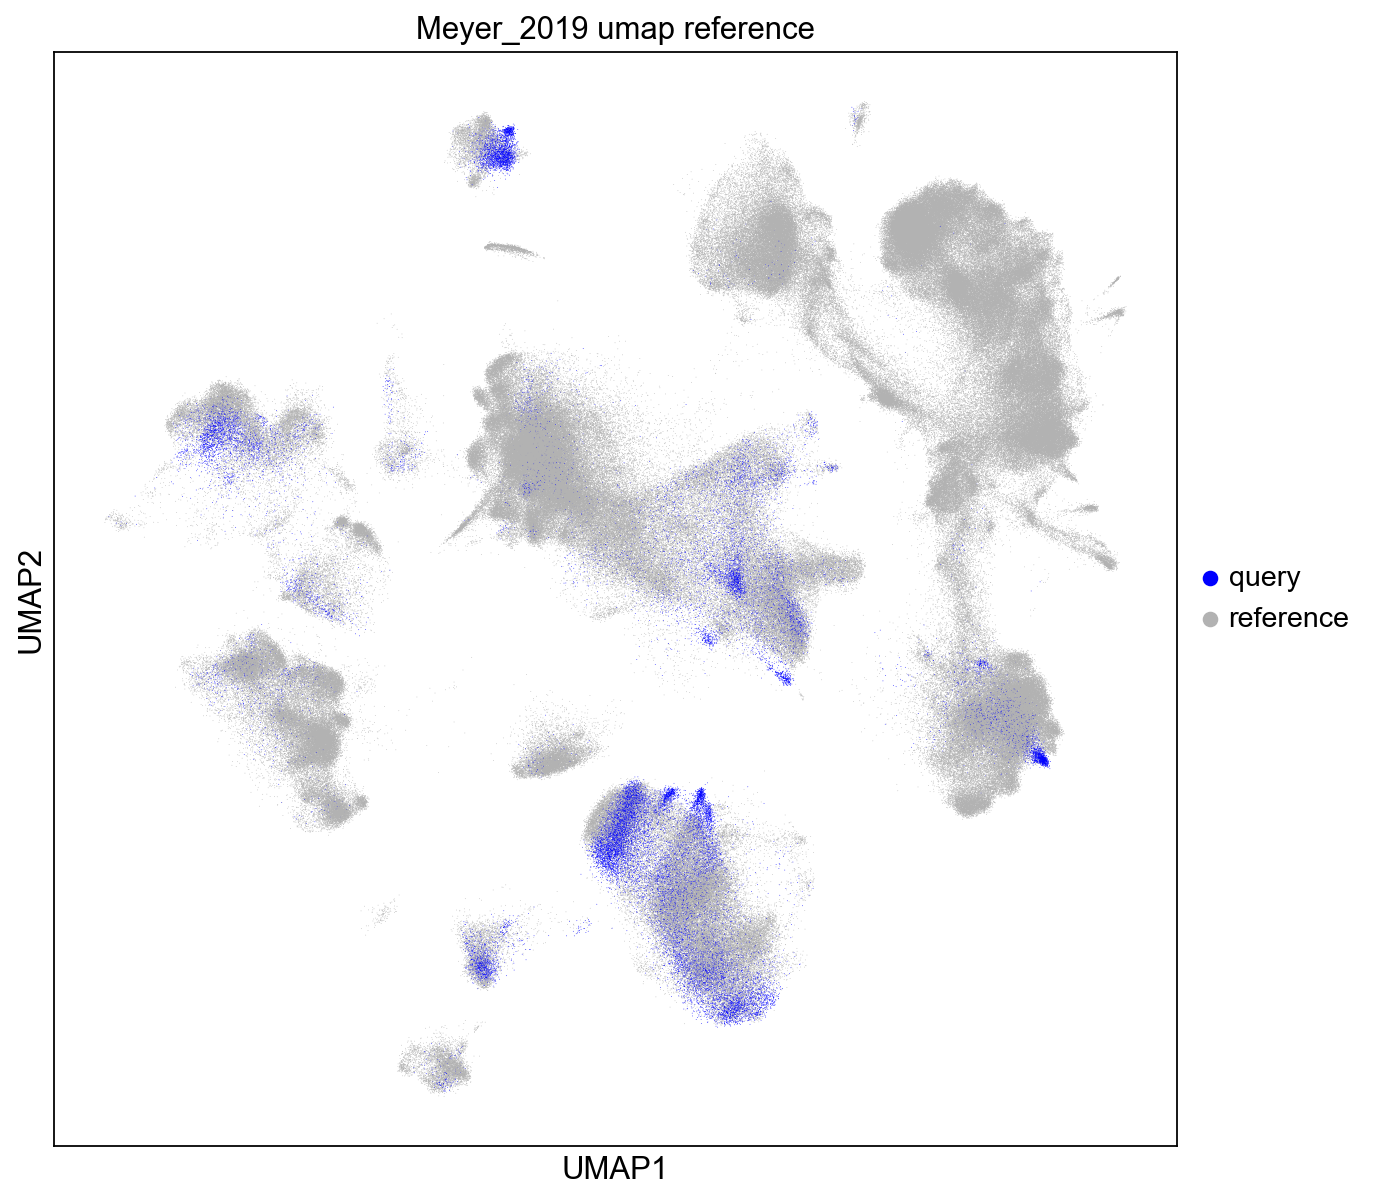

In [16]:
plotter.plot_umap(
    adata=adata, color_query=query_color, title_stub=ident, mode="reference", save=False
)

### Main Pipeline

Initialize the *MappingScoring* object. Pass the *AdataHandler* so that adata and workspace information is passed on.

In [17]:
scorer = MapAnalyzer.MappingScoring(adata_handler)

Logger directory already exists


In [18]:
adata = scorer.get_adata()

#### Calculate query mixing scores

In [19]:
# Opt 1: add scores from disc 
# scorer.add_scores(
#     os.path.join(scorer.workspace, ident, 'scores.csv')
# )

# Opt 2: compute scores
scorer.calculate_mixing_scores(
    adata = adata,
    verbose = False,
    save = True,
)

100%|██████████| 31/31 [03:24<00:00,  6.58s/it]


**Baseline calculation:**  
To compare our mapping to a upper bound, we calculate the scores for the integrated reference. For that we set one sample to query, while the other samples are set to reference (excluding the real query). By that we achieve a baseline for each celltype of how well different samples are integrated. We then can compare out mapping scores to the baseline to see, wether the mapping is of comparable quality to the integration. 

In [20]:
# Opt 1: add baseline from disc
# scorer.add_baseline(
#     os.path.join(scorer.workspace, 'baseline.csv'),
#     os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'celltypes.txt')
# )

# Opt 2: compute baseline
scorer.calculate_baseline(
    verbose = False,
    save = False,
)

100%|██████████| 31/31 [00:22<00:00,  1.40it/s]


add correction model for score correction for sample size:

In [21]:
# Option 1: add score transform from disc
# scorer.add_transformation(os.path.join(RESULTS_DIR, 'MapAnalyzer_Results_3.0', 'transformation.csv'))

# Option 2: compute transformation
scorer.calculate_transformation(
    save = True
)

### Analyzing the Mapping with MapAnalyzer

In [22]:
adata = scorer.get_adata()

In [23]:
scorer.analyze_mapping()

2023-06-16 08:21:25.861682	Correcting the for sample size...
2023-06-16 08:21:29.504297	356C_0h: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC venous', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-06-16 08:21:29.757223	Correcting the for sample size...
2023-06-16 08:21:33.227618	356C_12h: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'Multiciliated (non-nasal)', 'NK cells', 'T cell lineage']
2023-06-16 08:21:33.478802	Correcting the for sample size...
2023-06-16 08:21:36.949267	356C_24h: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'EC venous', 'Fibroblast lineage', 'Interstitial macrophages', 'Monocytes', 'NK cells', 'T cell lineage']
2023-06-16 08:21:37.195709	Correcting the for sample size...
2023-06-16 08:21:40.624838	356C_72h: ['AT2', 'Alveolar macrophages', 'Dendritic cells', 'Fibroblast lineage', 'Interstitial macrop

In [24]:
scorer.sample_report

health_status excluded        fraction accepted
                 first      sum count                   
sample                                                  
356C_0h        healthy        0    10  0.000000     True
356C_12h       healthy        0     9  0.000000     True
356C_24h       healthy        0     9  0.000000     True
356C_72h       healthy        0     8  0.000000     True
368C_0h        healthy        0     5  0.000000     True
368C_12h       healthy        1     8  0.125000     True
368C_24h       healthy        2    10  0.200000     True
368C_72h       healthy        2    10  0.200000     True
390C_0h        healthy        0     8  0.000000     True
390C_12h       healthy        0    10  0.000000     True
390C_24h       healthy        0    12  0.000000     True
390C_72h       healthy        8    11  0.727273    False

In [25]:
scorer.report.to_csv(
    os.path.join(RESULTS_DIR, 'report.csv')
)

### Plotting the outcomes

In [26]:
report = scorer.report.loc

In [27]:
adata = adata[adata.obs.cell_label.isin(scorer.cell_types)]

In [28]:
adata

View of AnnData object with n_obs × n_vars = 447688 × 30
    obs: 'suspension_type', 'subject_ID', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmoni

/Users/apple/miniforge3/envs/mapqc/lib/python3.9/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Filtering is not performed


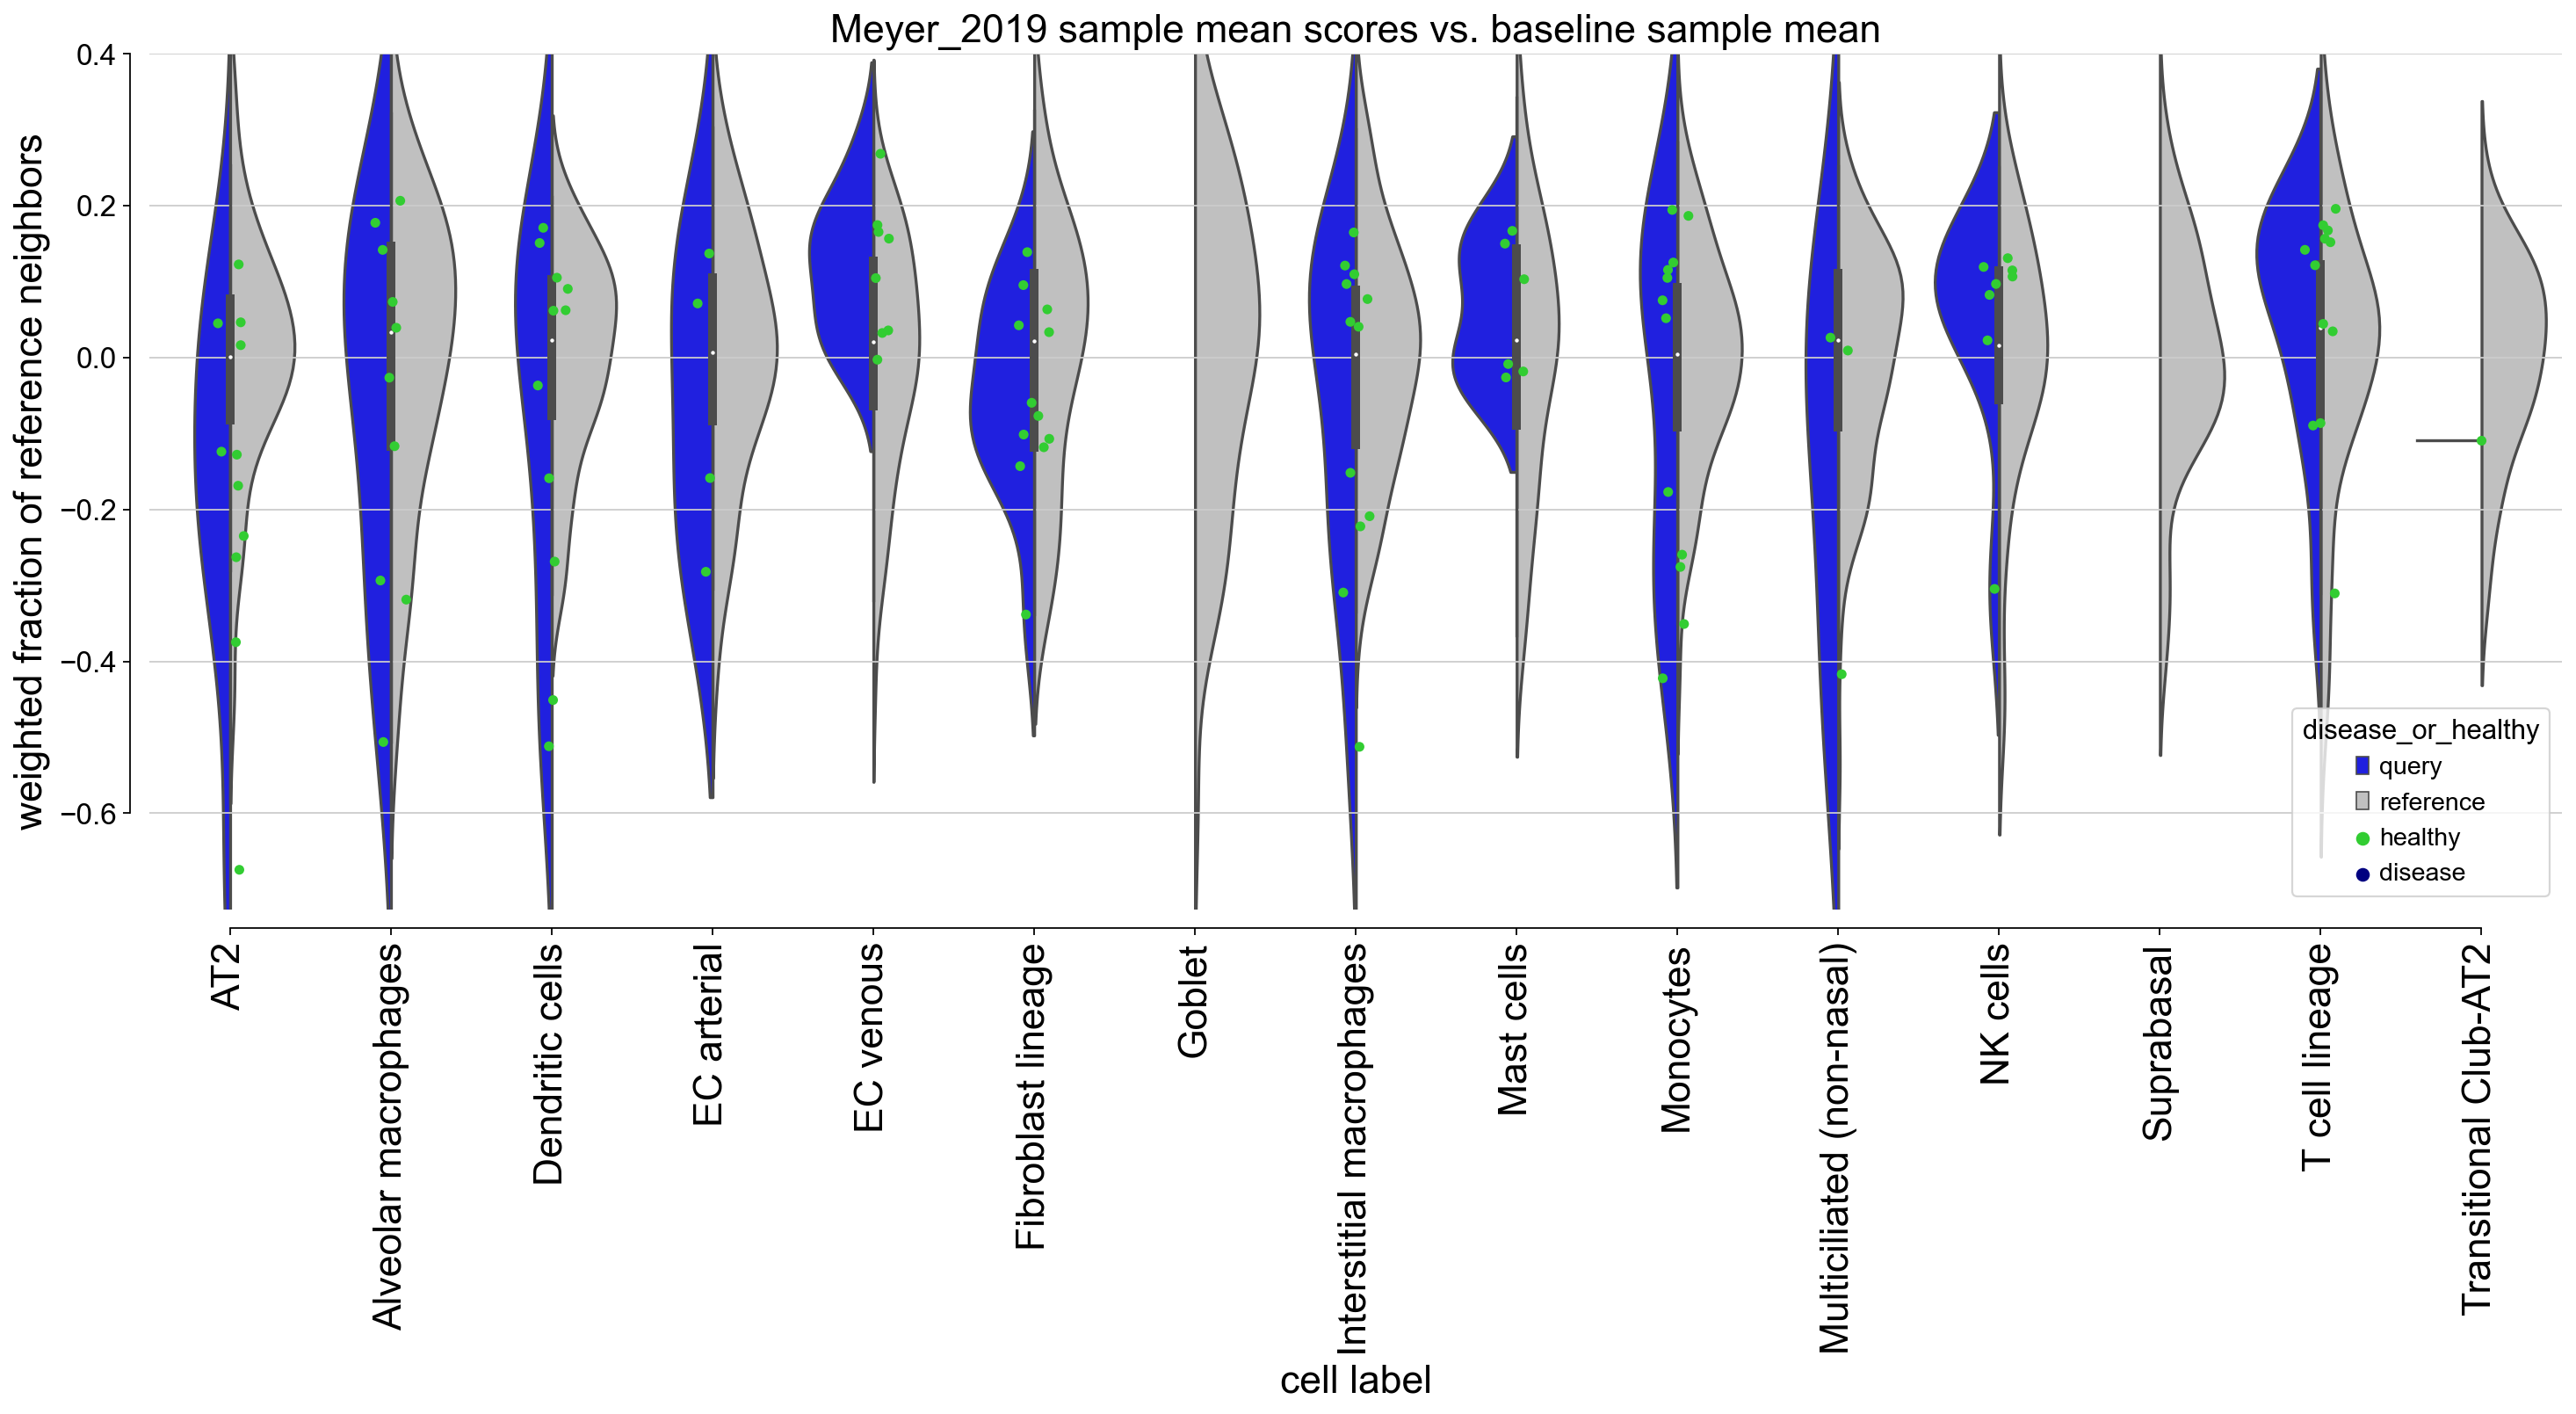

In [29]:
plotter.plot_baseline_comparison(
    adata,
    query_color,
    ident,
    disease=True,
    save=True,
    violin=True,
    #sample_filter=report,
    transform = os.path.join(RESULTS_DIR, 'transformation.csv')
)